# 4 — Katabatic slope flow

The remark in Section 2 of the manuscript. With equal eddy diffusivities of
momentum and heat, the stably stratified Prandtl slope-flow model has the same
form as the Ekman system,

$$(Ku')' = -a\,\theta,\qquad (K\theta')' = b\,u,\qquad a,b>0,$$

with $u$ the along-slope velocity and $\theta$ the temperature perturbation.
`coupled_forward` applies the same layer solver, so everything proved for the
Ekman case carries over unchanged.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
using ELES, LinearAlgebra, Printf
ENV["GKSwstype"] = "100"
using Plots
default(frame = :box, grid = false, size = (820, 300),
        lw = 2, legendfontsize = 7, titlefontsize = 9, guidefontsize = 8)
include(joinpath(@__DIR__, "..", "examples", "reference_shooting.jl"))
println("layer kinds: ", LAYER_KINDS)

layer kinds: (:constant, :linear, :quadratic, :exponential)


  Activating project at `<package>`
Precompiling packages...
   1273.6 ms  ✓ ELES
  1 dependency successfully precompiled in 2 seconds. 244 already precompiled.


## Constant diffusivity against the Prandtl closed form

In [2]:
slope = 6.0                                   # degrees
a = 9.81*sinpi(slope/180)/280                  # buoyancy coupling
b = 0.003*sinpi(slope/180)                     # stratification coupling
K0, theta0 = 0.1, -5.0
delta = sqrt(2K0)/(a*b)^(1/4)
u_exact(z) = theta0*sqrt(a/b)*exp(-z/delta)*sin(z/delta)
t_exact(z) = theta0*exp(-z/delta)*cos(z/delta)
z = collect(range(0, 100, length = 201))
model = LayerModel(collect(range(0, 100, length = 11)))
got = coupled_forward(model, fill(K0, model.nparameters), z; a, b,
                      lower = (0.0, theta0),
                      upper = (u_exact(100.0), t_exact(100.0)))
@printf("Prandtl length scale  %.2f m\n", delta)
@printf("max error in u        %.2e\n", maximum(abs.(got.u .- u_exact.(z))))
@printf("max error in theta    %.2e\n", maximum(abs.(got.v .- t_exact.(z))))

Prandtl length scale  13.66 m
max error in u        1.78e-15
max error in theta    1.78e-15


## A layered diffusivity

Nothing in the construction assumed a constant $K$: the same mixed-degree
partition used for the Ekman case works here.

parameters 8
interface jumps  5.1e-15 (value)  4.4e-17 (flux)
retained tail    1.5e-53


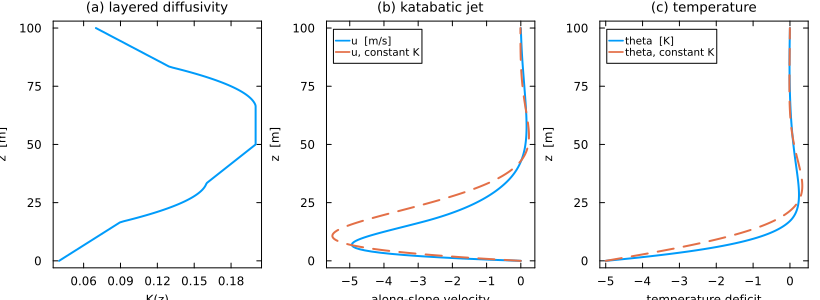

In [3]:
edges = collect(range(0, 100, length = 7))
degrees = [:linear, :quadratic, :linear, :constant, :quadratic, :linear]
layered = mixed_model(edges, degrees)
knots = [0.04, 0.09, 0.16, 0.20, 0.13, 0.07]
mids = [0.14, 0.18]                            # one per quadratic layer
values = vcat(knots, mids)
@printf("parameters %d\n", layered.nparameters)
sol = coupled_forward(layered, values, z; a, b, lower = (0.0, theta0),
                      upper = (0.0, 0.0))
jumps = interface_residuals(sol.solution)
@printf("interface jumps  %.1e (value)  %.1e (flux)\n", jumps.value, jumps.flux)
@printf("retained tail    %.1e\n", series_tail(sol.solution))
plot(
  plot(viscosity(sol.solution, z), z; xlabel = "K(z)", ylabel = "z  [m]",
       legend = false, title = "(a) layered diffusivity"),
  begin
    p = plot(sol.u, z; label = "u  [m/s]", xlabel = "along-slope velocity",
             ylabel = "z  [m]", title = "(b) katabatic jet")
    plot!(p, got.u, z; label = "u, constant K", ls = :dash)
  end,
  begin
    p = plot(sol.v, z; label = "theta  [K]", xlabel = "temperature deficit",
             ylabel = "z  [m]", title = "(c) temperature")
    plot!(p, got.v, z; label = "theta, constant K", ls = :dash)
  end;
  layout = (1, 3))